# PARTE 0: DATOS
**Paso 1: Preparación del entorno y carga de datos**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
url_viajes = "yellow_tripdata_2024-01.parquet"
url_zonas = "taxi_zone_lookup.csv"

columnas_a_cargar = [
    "tpep_pickup_datetime", 
    "PULocationID", 
    "trip_distance", 
    "fare_amount",
    "tip_amount"
]
viajes = pd.read_parquet(url_viajes, columns=columnas_a_cargar)
zonas = pd.read_csv(url_zonas)

# Paso 2: Evaluar lo cargado

In [2]:
viajes.head()

,tpep_pickup_datetime,PULocationID,trip_distance,fare_amount,tip_amount
0,2024-01-01 00:57:55,186,1.72,17.7,0.00
1,2024-01-01 00:03:00,140,1.80,10.0,3.75
2,2024-01-01 00:17:06,236,4.70,23.3,3.00
3,2024-01-01 00:36:38,79,1.40,10.0,2.00
4,2024-01-01 00:46:51,211,0.80,7.9,3.20


In [3]:
fecha_max = viajes["tpep_pickup_datetime"].max()
fecha_min = viajes["tpep_pickup_datetime"].min()

print(f"La fecha mínima:{fecha_min}, y la fecha máxima:{fecha_max}")

La fecha mínima:2002-12-31 22:59:39, y la fecha máxima:2024-02-01 00:01:15


In [4]:
viajes.dtypes

tpep_pickup_datetime    datetime64[us]
PULocationID                     int32
trip_distance                  float64
fare_amount                    float64
tip_amount                     float64
dtype: object

In [5]:
viajes.shape

(2964624, 5)

In [6]:
zonas.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


# Paso 3: Filtrar a Enero de 2024

In [7]:
viajes_enero = viajes[(viajes["tpep_pickup_datetime"]>="2024-01-01")&(viajes["tpep_pickup_datetime"]<"2024-02-01")]

fecha_max_en = viajes_enero["tpep_pickup_datetime"].max()
fecha_min_en = viajes_enero["tpep_pickup_datetime"].min()

print(f"La fecha mínima:{fecha_min_en}, y la fecha máxima:{fecha_max_en}")

La fecha mínima:2024-01-01 00:00:00, y la fecha máxima:2024-01-31 23:59:55


# Paso 4: Filtrar zonas

In [8]:
# 1. Viajes por zona de origen (solo enero)
conteo = viajes_enero.groupby("PULocationID").size().reset_index(name="viajes")

# 2. Cruzar con el catálogo de zonas (los nombres de la columna difieren)
zonas_filtradas = conteo.merge(zonas, left_on="PULocationID", right_on="LocationID", how="left")

# 3. Filtrar: 3,000 viajes o más y sin Unknown
zonas_pronostico = zonas_filtradas[
    (zonas_filtradas["viajes"] >= 3000)
    & (zonas_filtradas["Zone"] != "Unknown")
    & (zonas_filtradas["Borough"] != "Unknown")
]

print(len(zonas_pronostico))

58


In [9]:
zonas[(zonas["Zone"] == "Unknown") | (zonas["Borough"] == "Unknown")]

,LocationID,Borough,Zone,service_zone
263,264,Unknown,NaN,NaN


In [10]:
zonas_filtradas.head()

,PULocationID,viajes,LocationID,Borough,Zone,service_zone
0,1,295,1,EWR,Newark Airport,EWR
1,2,3,2,Queens,Jamaica Bay,Boro Zone
2,3,105,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,3568,4,Manhattan,Alphabet City,Yellow Zone
4,6,21,6,Staten Island,Arrochar/Fort Wadsworth,Boro Zone


# Paso 5: Viajes a serie de tiempo

In [11]:
# 1. Solo viajes de las zonas pronosticables
ids = sorted(zonas_pronostico["PULocationID"])
v = viajes_enero[viajes_enero["PULocationID"].isin(ids)].copy()

# 2. Redondear la hora de inicio hacia abajo y contar viajes por zona-hora
v["hora"] = v["tpep_pickup_datetime"].dt.floor("h")
conteo = v.groupby(["PULocationID", "hora"]).size().rename("viajes")

# 3. Todas las combinaciones zona-hora (1 ene a 1 feb), con 0 donde no hubo viajes
horas = pd.date_range("2024-01-01 00:00", "2024-02-01 23:00", freq="h")
indice = pd.MultiIndex.from_product([ids, horas], names=["PULocationID", "hora"])
demanda = conteo.reindex(indice, fill_value=0).reset_index()

# 4. El 1 de febrero es el "mañana": no hay datos reales, así que va vacío (no 0)
demanda.loc[demanda["hora"] >= "2024-02-01", "viajes"] = np.nan

In [12]:
print(demanda.shape)
print(demanda["viajes"].sum(), len(v))
print(demanda["viajes"].isna().sum())

(44544, 3)
2885953.0 2885953
1392


In [13]:
demanda.head()

,PULocationID,hora,viajes
0,4,2024-01-01 00:00:00,25.0
1,4,2024-01-01 01:00:00,29.0
2,4,2024-01-01 02:00:00,34.0
3,4,2024-01-01 03:00:00,31.0
4,4,2024-01-01 04:00:00,32.0


# PARTE 1: PRONOSTICO
**Las variables lags y calendario**

In [14]:
# 1. Ordenar: el shift depende del orden
demanda = demanda.sort_values(by=["PULocationID", "hora"]).reset_index(drop=True)

# 2. Lags: viajes pasados DE LA MISMA ZONA
for k in [24, 48, 167, 168, 169]:
    demanda[f"lag_{k}"] = demanda.groupby(["PULocationID"])["viajes"].shift(k)

# 3. Promedio del día anterior (media de viajes por hora del día anterior)
#    Pista: ¿cómo sacas la media de las últimas 24 horas, sin incluir las horas del día actual?
demanda["media_dia_ant"] = demanda.groupby("PULocationID")["viajes"].transform(lambda x: x.shift(24).rolling(window=24, min_periods=24).mean())

# 4. Calendario (pista: el accesor .dt de la columna "hora")
demanda["hora_dia"] = demanda["hora"].dt.hour
demanda["dia_semana"] = demanda["hora"].dt.day_of_week
demanda["feriado"] = (demanda["hora"].dt.date == datetime.date(2024, 1, 15)).astype(int) # 1 si es el 15 de enero de 2024, 0 si no

# 5. La zona como categoría (para XGBoost)
demanda["zona"] = demanda["PULocationID"].astype("category")

In [15]:
print(demanda["feriado"].sum())
print(demanda["zona"].dtype, demanda["zona"].nunique())
demanda[demanda["PULocationID"] == demanda["PULocationID"].iloc[0]].iloc[[0, 24, 168, 200]][["hora", "viajes", "lag_24", "lag_168", "media_dia_ant"]]

1392
category 58


,hora,viajes,lag_24,lag_168,media_dia_ant
0,2024-01-01 00:00:00,25.0,NaN,NaN,NaN
24,2024-01-02 00:00:00,1.0,25.0,NaN,NaN
168,2024-01-08 00:00:00,1.0,30.0,25.0,6.500000
200,2024-01-09 08:00:00,3.0,3.0,6.0,1.291667


# Separación entrenamiento, prueba y futuro
*Decisión conservar las lags_168 vacias: “las conservé porque son 7 de los 24 días de entrenamiento, y descartarlas sería perder casi un tercio de los datos. XGBoost maneja los vacíos solo.” Si más adelante te sobra tiempo, puedes entrenar una versión sin ellas y comparar el error.*

In [16]:
VARIABLES = ["lag_24", "lag_48", "lag_167", "lag_168", "lag_169", "media_dia_ant", "hora_dia","dia_semana", "feriado", "zona"]

entrenamiento = demanda[ (demanda["hora"] < "2024-01-25" ) ]
prueba        = demanda[ (demanda["hora"] >= "2024-01-25") & (demanda["hora"] < "2024-02-01") ]
futuro        = demanda[ (demanda["hora"] >= "2024-02-01") ]

# Pista: ¿qué filas de entrenamiento tienen NaN en lag_168 y no sirven para aprender?

In [17]:
print(len(entrenamiento), len(prueba), len(futuro), len(demanda))

33408 9744 1392 44544


# Entrenar modelo

In [18]:
entrenamiento.head()

,PULocationID,hora,viajes,lag_24,lag_48,lag_167,lag_168,lag_169,media_dia_ant,hora_dia,dia_semana,feriado,zona
0,4,2024-01-01 00:00:00,25.0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,4
1,4,2024-01-01 01:00:00,29.0,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,4
2,4,2024-01-01 02:00:00,34.0,NaN,NaN,NaN,NaN,NaN,NaN,2,0,0,4
3,4,2024-01-01 03:00:00,31.0,NaN,NaN,NaN,NaN,NaN,NaN,3,0,0,4
4,4,2024-01-01 04:00:00,32.0,NaN,NaN,NaN,NaN,NaN,NaN,4,0,0,4


In [19]:
import xgboost as xgb

CUANTILES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]     # 9 valores



modelo = xgb.XGBRegressor(
    objective="reg:quantileerror",
    quantile_alpha=np.array(CUANTILES),
    tree_method="hist",
    enable_categorical=True,
    n_estimators=250,
    max_depth=5,
    learning_rate=0.05,
)


modelo.fit(entrenamiento[VARIABLES], entrenamiento["viajes"])

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:quantileerror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from skl

In [20]:
pred = modelo.predict(prueba[VARIABLES])      # forma: (9744, 9)
pred = np.sort(pred, axis=1)                   # ¿por qué ordenar?

pred.shape

(9744, 9)

# Evaluar modelo

In [21]:
real = prueba["viajes"].to_numpy()
p10, p50, p90 = pred[:, 0], pred[:, 4], pred[:, 8]

mae_modelo   = np.mean(np.abs(real - p50))
mae_semana   = np.mean(np.abs(real - prueba["lag_168"]))
mae_ayer     = np.mean(np.abs(real - prueba["lag_24"]))      # regla "igual que ayer"

cobertura = np.mean((real >= p10) & (real <= p90))

print(mae_modelo, mae_semana, mae_ayer, cobertura)

12.550210382341131 11.881773399014778 21.286330049261085 0.8851600985221675


**Resultaods de MAE**
- mae_modelo 12.550210382341131
- mae_semana 11.881773399014778
- mae_ayer 21.286330049261085
- cobertura 0.8851600985221675

In [22]:
# 1. Calibración de cada cuantil: ¿qué fracción de reales queda por debajo?
for i, q in enumerate(CUANTILES):
    print(q, np.mean(real <= pred[:, i]))     # debería parecerse a q

# 2. Cobertura solo en horas con demanda "no trivial"
mascara = p90 > 5                            # ¿qué umbral elegirías?
cobertura_activa = np.mean(((real >= p10) & (real <= p90))[mascara])

0.1 0.07173645320197045
0.2 0.17467159277504105
0.3 0.27873563218390807
0.4 0.3817733990147783
0.5 0.4965106732348112
0.6 0.6122742200328407
0.7 0.7300903119868637
0.8 0.8494458128078818
0.9 0.9568965517241379


In [23]:
# 1. Entrenamiento sin las filas que no tienen semana anterior
ent2 = entrenamiento[ entrenamiento["lag_168"].notna() ]     # ¿cuántas filas quedan?
print(len(ent2))

# 2. Un modelo nuevo, con los MISMOS parámetros que el primero
modelo2 = xgb.XGBRegressor(
    objective="reg:quantileerror",
        quantile_alpha=np.array(CUANTILES),
        tree_method="hist",
        enable_categorical=True,
        n_estimators=250,
        max_depth=5,
        learning_rate=0.05,
)                              # mismos parámetros
modelo2.fit(ent2[VARIABLES], ent2["viajes"])

# 3. Sus predicciones (con otro nombre, para no pisar las del modelo original)
pred2 = modelo2.predict(prueba[VARIABLES])
pred2 = np.sort(pred2, axis=1)

# 4. Las métricas, ahora sobre pred2
p10_2, p50_2, p90_2 = pred2[:, 0], pred2[:, 4], pred2[:, 8]
mae_modelo2 = np.mean(np.abs(real - p50_2))
cobertura2  = np.mean((real >= p10_2) & (real <= p90_2))
print(mae_modelo2, cobertura2)

pred2 = modelo2.predict(prueba[VARIABLES])     
pred2 = np.sort(pred, axis=1)                   

pred.shape

23664
11.97450363559047 0.8955254515599343


(9744, 9)

**Resultados MAE modelo 2**
- largo de ent2 23664
- mae modelo2 11.97450363559047 
- cobertura2  0.8955254515599343

In [24]:
zonas_pronostico.head()

,PULocationID,viajes,LocationID,Borough,Zone,service_zone
3,4,3568,4,Manhattan,Alphabet City,Yellow Zone
11,13,15877,13,Manhattan,Battery Park City,Yellow Zone
22,24,7849,24,Manhattan,Bloomingdale,Yellow Zone
39,41,6832,41,Manhattan,Central Harlem,Boro Zone
40,42,3152,42,Manhattan,Central Harlem North,Boro Zone


**Evaluación error por zona**

In [25]:
prueba_eval = prueba.assign(error=np.abs(real - p50_2))
por_zona = prueba_eval.groupby("PULocationID")["error"].mean().sort_values(ascending=False).reset_index()


zonas_error = por_zona.merge(zonas_pronostico, left_on="PULocationID", right_on="LocationID", how="left")
zonas_error[["Zone", "Borough", "error"]].head(10)

,Zone,Borough,error
0,Penn Station/Madison Sq West,Manhattan,30.328421
1,Upper East Side South,Manhattan,29.805687
2,JFK Airport,Queens,27.901625
3,Midtown Center,Manhattan,27.200500
4,Lincoln Square East,Manhattan,26.828115
5,West Chelsea/Hudson Yards,Manhattan,24.906062
6,Upper East Side North,Manhattan,23.888438
7,LaGuardia Airport,Queens,22.586060
8,Times Sq/Theatre District,Manhattan,20.750038
9,East Village,Manhattan,20.447795


**Guardar archivos para API**

In [26]:
demanda.head()

,PULocationID,hora,viajes,lag_24,lag_48,lag_167,lag_168,lag_169,media_dia_ant,hora_dia,dia_semana,feriado,zona
0,4,2024-01-01 00:00:00,25.0,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0,4
1,4,2024-01-01 01:00:00,29.0,NaN,NaN,NaN,NaN,NaN,NaN,1,0,0,4
2,4,2024-01-01 02:00:00,34.0,NaN,NaN,NaN,NaN,NaN,NaN,2,0,0,4
3,4,2024-01-01 03:00:00,31.0,NaN,NaN,NaN,NaN,NaN,NaN,3,0,0,4
4,4,2024-01-01 04:00:00,32.0,NaN,NaN,NaN,NaN,NaN,NaN,4,0,0,4


In [27]:
# 1. El modelo 2
modelo2.save_model("api/modelo_pronostico.ubj")

# 2. Las filas que la API va a consultar (25 de enero al 1 de febrero)
demanda_api = demanda[ (demanda["hora"] >= "2024-01-25") ][VARIABLES + ["PULocationID" ,"hora", "viajes"] ]
demanda_api.to_parquet("api/demanda.parquet", index=False)

# 3. Nombre y distrito de las 58 zonas
zonas_api = zonas_pronostico[ ["LocationID", "Zone", "Borough"] ]
zonas_api.to_csv("api/zonas.csv", index=False)



**Comprobaciones de los archivos API**

In [28]:
import os
print(os.path.getsize("api/modelo_pronostico.ubj") / 1e6, "MB")

9.515434 MB


In [29]:
m = xgb.XGBRegressor()
m.load_model("api/modelo_pronostico.ubj")
print(np.allclose(m.predict(prueba[VARIABLES]), modelo2.predict(prueba[VARIABLES])))

True


In [30]:
demanda_api.shape

(11136, 13)

In [31]:
demanda_api["hora"].max()


Timestamp('2024-02-01 23:00:00')

In [32]:
demanda_api.groupby("PULocationID").size().unique()

array([192])

In [33]:
print(xgb.__version__)

3.4.1


**Parte de comprobación del problema del error 500 en pronostico**

In [34]:
d = pd.read_parquet("api/demanda.parquet")
print(d["zona"].dtype)
print(entrenamiento["zona"].dtype)
print(entrenamiento["zona"].cat.categories.dtype)

#m.predict(d[VARIABLES])     # ¿falla igual que la API?


CATEGORIAS = np.array(sorted(zonas_pronostico["LocationID"]), dtype="int64")
d["zona"] = pd.Categorical(d["PULocationID"], categories=CATEGORIAS)

int64
category
int64


In [35]:
print(d["zona"].dtype)
print(m.predict(d[VARIABLES]).shape)

category
(11136, 9)


# PARTE 2: SEGMENTACION
**Segmentacion de zonas**

In [36]:
# 1. Zonas con al menos 500 viajes en enero (sin Unknown)
conteo = viajes_enero.groupby("PULocationID").size()
unknown = zonas.loc[(zonas["Zone"] == "Unknown") | (zonas["Borough"] == "Unknown"), "LocationID"]
ids_seg = conteo[(conteo >= 500) & (~conteo.index.isin(unknown))].index

# 2. Viajes de las zonas filtradas, con la hora del día y marcados los fines de semana
v = viajes_enero[viajes_enero["PULocationID"].isin(ids_seg)].copy()
v["hora_dia"] = v["tpep_pickup_datetime"].dt.hour
v["fin_semana"] = v["tpep_pickup_datetime"].dt.dayofweek.isin([5,6]) # sábado o domingo

# 3. Distancia y tarifa, descartando viajes con valors menores o iguales a cero
v_pos = v[(v["trip_distance"] > 0) & (v["fare_amount"] > 0)]

g = v.groupby("PULocationID")
g_pos = v_pos.groupby("PULocationID")

# 4. Una fila por zona
perfil = pd.DataFrame({
    "viajes_dia": conteo[ids_seg]/31,
    "dist_mediana": g_pos["trip_distance"].median(),
    "tarifa_mediana": g_pos["fare_amount"].median(),
    "propina_mediana": g["tip_amount"].median(),
    "pct_finde": g["fin_semana"].mean(),
    "pct_6_10": v["hora_dia"].between(6, 10).groupby(v["PULocationID"]).mean(),
    "pct_16_20": v["hora_dia"].between(16, 20).groupby(v["PULocationID"]).mean(),
    "pct_22_5": ((v["hora_dia"] >= 22) | (v["hora_dia"] <= 5)).groupby(v["PULocationID"]).mean(),
})

print(len(ids_seg), perfil.shape)
print(perfil.isna().sum())

101 (101, 8)
viajes_dia         0
dist_mediana       0
tarifa_mediana     0
propina_mediana    0
pct_finde          0
pct_6_10           0
pct_16_20          0
pct_22_5           0
dtype: int64


**Preparar los datos (log y escalado) y elegir cuántos grupos usar (k)**

*{2: 0.3456669406080788, 3: 0.38227997327170166, 4: 0.41010507228593246, 5: 0.42374349064028133, 6: 0.39186236586099077, 7: 0.38028398216228626}

*k elegido 5*

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Viajes por día en escala logarítmica
X = perfil.copy()
X["viajes_dia"] = np.log1p(X["viajes_dia"])

# 2. Escalar las 8 columnas
escalador = StandardScaler()
X_esc = escalador.fit_transform(X)

# 3. Silueta para k = 2 a 7
silueta = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_esc)
    silueta[k] = silhouette_score(X_esc, etiquetas)

print(silueta)

{2: 0.3456669406080788, 3: 0.38227997327170166, 4: 0.41010507228593246, 5: 0.42374349064028133, 6: 0.39186236586099077, 7: 0.38028398216228626}


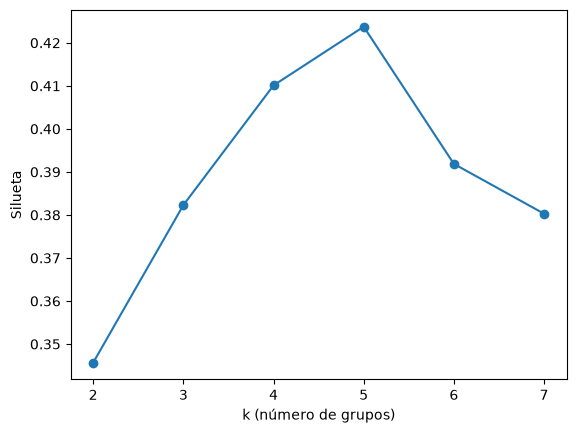

In [38]:
plt.plot(list(silueta.keys()), list(silueta.values()), marker="o")
plt.xlabel("k (número de grupos)")
plt.ylabel("Silueta")
plt.show()

**Kmeans definitivo ajustado en k 5**
2. ¿Cuántas zonas tiene cada grupo?
grupo
0    37
1    12
2    44
3     3
4     5

In [39]:
# 1. K-Means definitivo
km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
perfil["grupo"] = km5.fit_predict(X_esc)

# 2. ¿Cuántas zonas tiene cada grupo?
perfil["grupo"].value_counts().sort_index()

# 3. Perfil promedio de cada grupo
perfil.groupby("grupo").mean()

,viajes_dia,dist_mediana,tarifa_mediana,propina_mediana,pct_finde,pct_6_10,pct_16_20,pct_22_5
grupo,,,,,,,,
0,48.813426,3.885946,22.800541,0.218919,0.228147,0.319128,0.200384,0.184949
1,700.196237,2.639167,16.727917,1.710833,0.437132,0.093256,0.205730,0.494721
2,1732.277859,1.918864,13.293182,2.665227,0.247875,0.175746,0.330535,0.134796
3,2656.505376,12.096667,50.300000,9.980000,0.232961,0.148199,0.341170,0.173714
4,29.141935,10.772000,56.954000,1.000000,0.272815,0.226141,0.242045,0.236076


In [40]:
print(len(X) == len(perfil))
perfil.groupby("grupo").mean().round(2)

True


,viajes_dia,dist_mediana,tarifa_mediana,propina_mediana,pct_finde,pct_6_10,pct_16_20,pct_22_5
grupo,,,,,,,,
0,48.81,3.89,22.80,0.22,0.23,0.32,0.20,0.18
1,700.20,2.64,16.73,1.71,0.44,0.09,0.21,0.49
2,1732.28,1.92,13.29,2.67,0.25,0.18,0.33,0.13
3,2656.51,12.10,50.30,9.98,0.23,0.15,0.34,0.17
4,29.14,10.77,56.95,1.00,0.27,0.23,0.24,0.24


In [41]:
nombres = perfil.reset_index().merge(zonas, left_on="PULocationID", right_on="LocationID")
nombres.groupby("grupo")["Zone"].apply(lambda z: list(z)[:6])

grupo
0    [Astoria, Bedford, Boerum Hill, Brooklyn Heigh...
1    [Alphabet City, East Village, East Williamsbur...
2    [Battery Park, Battery Park City, Bloomingdale...
3      [East Elmhurst, JFK Airport, LaGuardia Airport]
4    [Baisley Park, Flushing Meadows-Corona Park, J...
Name: Zone, dtype: object

In [42]:
medias = perfil.groupby("grupo").mean()

nombres = {}
nombres[ medias["propina_mediana"].idxmax() ] = "Aeropuertos"
nombres[ medias["pct_22_5"].idxmax() ] = "Vida nocturna"
nombres[medias["tarifa_mediana"].idxmax()] = "Zonas remotas de viajes largos"
nombres[ medias["dist_mediana"].idxmin()] = "Manhattan central"
nombres[medias["pct_6_10"].idxmax()] = "Barrios periféricos"

perfil["nombre_grupo"] = perfil["grupo"].map(nombres)

In [43]:
perfil["nombre_grupo"].value_counts()

nombre_grupo
Manhattan central                 44
Barrios periféricos               37
Vida nocturna                     12
Zonas remotas de viajes largos     5
Aeropuertos                        3
Name: count, dtype: int64

**PCA a 2 componentes**
1. [PC1: 0.38824382 PC2: 0.27060952] Total: 0.6588533387526843

In [44]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
comp = pca.fit_transform(X_esc)

perfil["pc1"] = comp[:, 0]
perfil["pc2"] = comp[:, 1]

print(pca.explained_variance_ratio_, pca.explained_variance_ratio_.sum())

[0.38824382 0.27060952] 0.6588533387526843


**Guardar archivo CSV zonas_segmentadas**

In [45]:
tabla = perfil.reset_index().merge(zonas[["LocationID", "Zone", "Borough"]], left_on="PULocationID", right_on="LocationID")
tabla.to_csv("app/data/zonas_segmentadas.csv", index=False)
print(tabla.shape)

(101, 16)


In [46]:
tabla.head()

,PULocationID,viajes_dia,dist_mediana,tarifa_mediana,propina_mediana,pct_finde,pct_6_10,pct_16_20,pct_22_5,grupo,nombre_grupo,pc1,pc2,LocationID,Zone,Borough
0,4,115.096774,2.08,14.2,2.02,0.549327,0.135090,0.129204,0.591648,1,Vida nocturna,-0.090101,4.601393,4,Alphabet City,Manhattan
1,7,58.419355,2.96,18.5,0.00,0.315295,0.286030,0.214246,0.205411,0,Barrios periféricos,-1.015387,0.408224,7,Astoria,Queens
2,10,32.225806,14.19,70.0,0.00,0.229229,0.267267,0.277277,0.181181,4,Zonas remotas de viajes largos,-3.532372,-0.238240,10,Baisley Park,Queens
3,12,28.225806,4.60,24.7,2.66,0.262857,0.062857,0.289143,0.024000,2,Manhattan central,0.182621,-0.323110,12,Battery Park,Manhattan
4,13,512.161290,3.51,19.8,3.57,0.174655,0.158342,0.428167,0.048057,2,Manhattan central,1.663693,-1.675865,13,Battery Park City,Manhattan


In [47]:
v.head()

,tpep_pickup_datetime,PULocationID,trip_distance,fare_amount,tip_amount,hora_dia,fin_semana
0,2024-01-01 00:57:55,186,1.72,17.7,0.00,0,False
1,2024-01-01 00:03:00,140,1.80,10.0,3.75,0,False
2,2024-01-01 00:17:06,236,4.70,23.3,3.00,0,False
3,2024-01-01 00:36:38,79,1.40,10.0,2.00,0,False
4,2024-01-01 00:46:51,211,0.80,7.9,3.20,0,False


real = prueba["viajes"].to_numpy()
p10, p50, p90 = pred[:, 0], pred[:, 4], pred[:, 8]

mae_modelo   = np.mean(np.abs(real - p50))
mae_semana   = np.mean(np.abs(real - prueba["lag_168"]))
mae_ayer     = np.mean(np.abs(real - prueba["lag_24"]))      # regla "igual que ayer"

cobertura = np.mean((real >= p10) & (real <= p90))

print(mae_modelo, mae_semana, mae_ayer, cobertura)

In [51]:
error_grupo.head()

,nombre_grupo,mean,count
0,Aeropuertos,18.369809,504
1,Barrios periféricos,2.493354,672
2,Manhattan central,12.767882,7224
3,Vida nocturna,10.052432,1344


**Exportando datos a ficha.json**

In [49]:
import json

# 1. Calibración del modelo 2: fracción de reales por debajo de cada cuantil
calibracion = {str(q): float(np.mean(real <= pred2[:, i])) for i, q in enumerate(CUANTILES)}

# 2. Error por tipo de zona (por hora-zona, con la mediana del modelo 2)
ev = prueba.assign(error=np.abs(real - p50_2))
ev = ev.merge(perfil[["nombre_grupo"]].reset_index(), on="PULocationID", how="left")
error_grupo = ev.groupby("nombre_grupo")["error"].agg(["mean", "count"]).reset_index()

# 3. Todo en un solo archivo
cifras = {
    "mae_modelo": float(np.mean(np.abs(real-p50_2))),
    "mae_semana": float(np.mean(np.abs(real-prueba["lag_168"]))),
    "mae_ayer": float(np.mean(np.abs(real-prueba["lag_24"]))),
    "cobertura": float(np.mean((real >= p10_2) & (real <= p90_2))),
    "horas_evaluadas": len(prueba),
    "zonas": int(prueba["PULocationID"].nunique()),
    "calibracion": calibracion,
    "error_por_grupo": error_grupo.to_dict("records"),
    "zonas_mas_error": zonas_error[["Zone", "Borough", "error"]].head(5).to_dict("records"),
}
with open("app/data/ficha.json", "w", encoding="utf-8") as f:
    json.dump(cifras, f, ensure_ascii=False, indent=2)

In [52]:
print(cifras["mae_modelo"], cifras["mae_semana"], cifras["mae_ayer"], cifras["cobertura"])
print(error_grupo)

11.97450363559047 11.881773399014778 21.286330049261085 0.8955254515599343
          nombre_grupo       mean  count
0          Aeropuertos  18.369809    504
1  Barrios periféricos   2.493354    672
2    Manhattan central  12.767882   7224
3        Vida nocturna  10.052432   1344
